# ProbLog4Fairness: mitigating bias by modeling it in a module integrated in a standard PyTorch pipeline

Datasets often contain bias, which you want to avoid when learning a model from that data. In this demo, we show how to use ProbLog4Fairness to learn a fair model despite label bias in the dataset.

ProbLog4Fairness lets you write down *how* bias arose, as a small probabilistic logic program,
and then wrap your existing PyTorch classifier in it.

```python
model = LabelBiasModule(classifier, tpr_not_a, tpr_a, fpr_not_a, fpr_a)   # classifier is any nn.Module -> (batch, 1) probability
```

`model` is an ordinary `nn.Module`. You train it with your usual loop on the biased labels; the wrapper
absorbs the bias, so the classifier inside it learns the *unbiased* label. At test time you throw the
wrapper away and use the classifier directly.

## 1. Dataset

This notebook uses the [student dataset](https://www.kaggle.com/datasets/daphnelenders/performance-vs-predicted-performance), which contains students with both the
grade students received and the grade a human grader predicted for them. Male and female students pass at a similar rate
in reality (0.81 vs 0.84), but graders predicted male students to pass far less often (0.58 vs 0.76).

We build a dataset that only contains the biased labels and one that only contains the real fair labels.

In [1]:
import random

import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

from src import set_seed
from src.dataset import TabularDataset
from experiments.student.dataset import load_data_with_biased_and_unbiased_grades, preprocess_data

set_seed(0)
# Set the sensitive attribute to be 'sex': 0 = female (privileged), 1 = male
SENSITIVE_IDX = 0

# Load the data and prepare as a training dataset with biased data and a test set with fair labels
data, categorical_attributes = load_data_with_biased_and_unbiased_grades()
fair, biased = preprocess_data(data, categorical_attributes)

ds_fair = TabularDataset(fair.features, fair.labels.ravel(), SENSITIVE_IDX, fair.feature_names)
ds_biased = TabularDataset(biased.features, biased.labels.ravel(), SENSITIVE_IDX, biased.feature_names)

train_idx, test_idx = train_test_split(range(len(ds_fair)), test_size=0.2, random_state=0, stratify=ds_fair.labels)
train_set = Subset(ds_biased, train_idx)
test_biased, test_fair = Subset(ds_biased, test_idx), Subset(ds_fair, test_idx)
train_loader_biased_dataset = DataLoader(train_set, batch_size=64, shuffle=True)
train_loader_fair_dataset = DataLoader(Subset(ds_fair, train_idx), batch_size=64, shuffle=True)

# Show a random example from the dataset
a, features, y = ds_biased[random.Random().randrange(len(ds_biased))]
print(f"Example student from tabular dataset", pd.Series(features.numpy(), index=ds_biased.feature_names),sep='\n')
print(f"\nsensitive attribute (sex) = {a.item()}, biased label (passed course) = {y.item()}")

Example student from tabular dataset
sex                  1.0
studytime            1.0
freetime             3.0
Walc                 2.0
goout                4.0
Parents_edu          2.0
absences             7.0
romantic=no          1.0
romantic=yes         0.0
reason=course        0.0
reason=home          1.0
reason=other         0.0
reason=reputation    0.0
dtype: float32

sensitive attribute (sex) = 1, biased label (passed course) = 0


## 2. Building the model

First we create a PyTorch classifier that we want to train to predict the label.

Then we create a label bias module by specifying the rates at which fair label was changed into a biased one.
`tpr` True Positive Rate is the rate of how often the given label is positive when the unbiased label is positive.
`fpr` False Positive Rate is the rate of how often the given label is positive when the unbiased label is negative.

We can estimate the relevant rates from the data, when we have both labels available for a subset. These rates serve as the bias assumptions that we don't want our model to learn.

We can then wrap our classifier with this bias_model.

In [2]:
import logging, warnings
logging.getLogger().setLevel(logging.ERROR)  # silence aif360's optional-dep notices
logging.getLogger('pytorch_lightning.utilities.rank_zero').setLevel(logging.WARNING)  # drop Lightning's device banner, keep its model summary
warnings.filterwarnings('ignore', category=UserWarning)

from torch import nn
from src.fairness_module import LabelBiasModule

# An ordinary PyTorch classifier: (batch, n_features) -> (batch, 1) probability.
torch.manual_seed(0)
problog_classifier = nn.Sequential(
    nn.Linear(ds_fair.features.shape[1], 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, 1), nn.Sigmoid(),
)

# Bias is added as rates of how often someone gets a prediction that it shouldn't have gotten
# a = 0 female/privileged, a = 1 male
# tpr = probability of a positive biased label given that the student has a positive fair label
# fpr = probability of a positive biased label given that the student has a negative fair label
# Here we assume no positive bias: nobody is flipped from fail to pass, in either group (fpr = 0).
# We model that female students are predicted to pass the course only in 85% of the cases given that they did pass the course
# While male students are predicted to pass the course only in 70% of the cases given that they did pass the course.
# Both are being biased against but more wrong predictions were made against male students.
# LabelBiasModule wraps the classifier in a biasing mechanism that turns its predictions
# into biased ones at these rates. The ProbLog program behind it is src/programs/label_bias.pl.
bias_model = LabelBiasModule(problog_classifier, tpr_not_a=0.85, tpr_a=0.70,
                             fpr_not_a=0, fpr_a=0, sensitive_index=SENSITIVE_IDX)

Note that the bias_model is an ordinary `nn.Module` taking `X` as input (it reads the sensitive attribute from column `SENSITIVE_IDX`) and outputting a probability of the *biased* label, computed from the classifier and the bias rates. Its weights train like any other module's.

## 3. Training

We can train the module we've built just like any classifier.

Here we train two additional models for demonstration purposes:
A lower baseline, which is the classifier directly trained on the biased data.
An upper baseline, which is the classifier directly trained on the fair data.

In [3]:
import copy
import pytorch_lightning as pl

from src.training import FocalLoss

class LightningModel(pl.LightningModule):
    """Trains a net on (a, X, y) batches. The bias model and a bare classifier share
    the same (X) -> probability signature, so the same loop trains either."""

    def __init__(self, net):
        super().__init__()
        self.net = net
        self.loss_fn = FocalLoss(alpha=1, gamma=2)

    def training_step(self, batch, batch_idx):
        a, X, y = batch
        p = self.net(X)
        loss = self.loss_fn(p.flatten(), y)
        self.log("loss", loss, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=3e-4)

# ProbLog4Fairness: the bias model wrapped around the classifier, trained directly on the biased labels
print("training ProbLog4Fairness: classifier + bias model on the biased labels",flush=True)
trainer = pl.Trainer(max_epochs=20, accelerator="cpu", logger=False, enable_checkpointing=False)
trainer.fit(LightningModel(bias_model), train_loader_biased_dataset)

# lower baseline: the classifier, trained directly on the biased labels
lower_baseline = copy.deepcopy(problog_classifier)
print("training the lower baseline: classifier straight on the biased labels",flush=True)
trainer = pl.Trainer(max_epochs=20, accelerator="cpu", logger=False, enable_checkpointing=False)
trainer.fit(LightningModel(lower_baseline), train_loader_biased_dataset)

# upper baseline: the classifier trained directly on the fair labels. This is the ideal scenario as if the bias never happened
print("training the upper baseline: classifier straight on the fair labels", flush=True)
upper_baseline = copy.deepcopy(problog_classifier)
trainer = pl.Trainer(max_epochs=20, accelerator="cpu", logger=False, enable_checkpointing=False)
trainer.fit(LightningModel(upper_baseline), train_loader_fair_dataset)

training ProbLog4Fairness: classifier + bias model on the biased labels



  | Name    | Type            | Params | Mode 
----------------------------------------------------
0 | net     | LabelBiasModule | 69.6 K | train
1 | loss_fn | FocalLoss       | 0      | train
----------------------------------------------------
69.6 K    Trainable params
0         Non-trainable params
69.6 K    Total params
0.279     Total estimated model params size (MB)
37        Modules in train mode
0         Modules in eval mode


Epoch 19: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 309.20it/s, loss=0.117]
training the lower baseline: classifier straight on the biased labels



  | Name    | Type       | Params | Mode 
-----------------------------------------------
0 | net     | Sequential | 69.6 K | train
1 | loss_fn | FocalLoss  | 0      | train
-----------------------------------------------
69.6 K    Trainable params
0         Non-trainable params
69.6 K    Total params
0.279     Total estimated model params size (MB)
11        Modules in train mode
0         Modules in eval mode


Epoch 19: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 468.23it/s, loss=0.100]
training the upper baseline: classifier straight on the fair labels



  | Name    | Type       | Params | Mode 
-----------------------------------------------
0 | net     | Sequential | 69.6 K | train
1 | loss_fn | FocalLoss  | 0      | train
-----------------------------------------------
69.6 K    Trainable params
0         Non-trainable params
69.6 K    Total params
0.279     Total estimated model params size (MB)
11        Modules in train mode
0         Modules in eval mode


Epoch 19: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 546.15it/s, loss=0.0659]


The wrapped model's loss settles higher, and it should: it can never predict a probability outside
`[fpr, tpr]`, because it is modelling labels it believes to be noisy. A lower loss against biased labels is
not the goal.

## 4. Testing

We test the trained models on two metrics: how well it predicts the fair labels and how unequally it treats the two groups.

Training with ProbLog4Fairness can remove the bias and improve accuracy on the fair labels.

Important to note: after training with the ProbLog4Fairness module, we test with the classifier directly using `bias_model.get_classifier()`, so that it predicts the fair label and not a biased label.

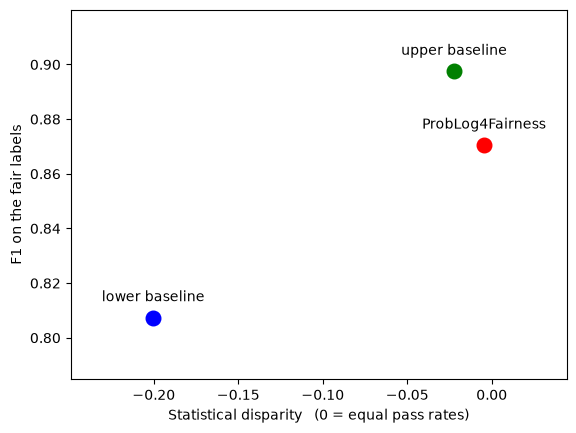

In [4]:
import matplotlib.pyplot as plt
from torchmetrics.functional.classification import binary_f1_score
from src.metrics import probabilistic_statistical_disparity

a_test, X_test, y_test = next(iter(DataLoader(test_fair, batch_size=len(test_fair))))

# For each model: how well it predicts the fair labels (F1),
# and how unequally it treats the two groups (statistical disparity).
for name, model, colour in [("lower baseline", lower_baseline, "blue"),
                            ("ProbLog4Fairness", bias_model.get_classifier(), "red"),
                            ("upper baseline", upper_baseline, "green")]:
    model.eval()
    with torch.no_grad():
        p = model(X_test).flatten()
    f1 = binary_f1_score(p, y_test).item()
    disparity = probabilistic_statistical_disparity((p > 0.5).float(), a_test)
    plt.scatter(disparity, f1, s=110, color=colour)
    plt.annotate(name, (disparity, f1), textcoords="offset points", xytext=(0, 12), ha="center")

plt.xlabel("Statistical disparity   (0 = equal pass rates)")
plt.ylabel("F1 on the fair labels")
plt.margins(0.25)
plt.show()

## More features

- **Other bias assumptions.** We can model other assumptions like *measurement bias*, where the bias is on one or more input features, and *historical bias*, where the bias on the input features also affects the label. Dedicated modules for these bias assumptions are available in `src/fairness_module.py`. Even more bias assumptions can be described by adding, modifying, or combining the logical rules for these bias assumptions, which can make it fit for your exact scenario.
- **Images.** This demo shows the method on tabular data but this technique also works with image classifiers, see the CelebA experiment.
- **Full paper.** See [the paper](https://ojs.aaai.org/index.php/AAAI/article/view/39033) for more details.